Dataset Shape: (569, 30)
Feature Names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Target Classes: [np.str_('malignant'), np.str_('benign')]

First Five Records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Model Accuracy: 0.9561

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


LIME EXPLANATION
Actual Class: malignant
Predicted Class: malignant


None

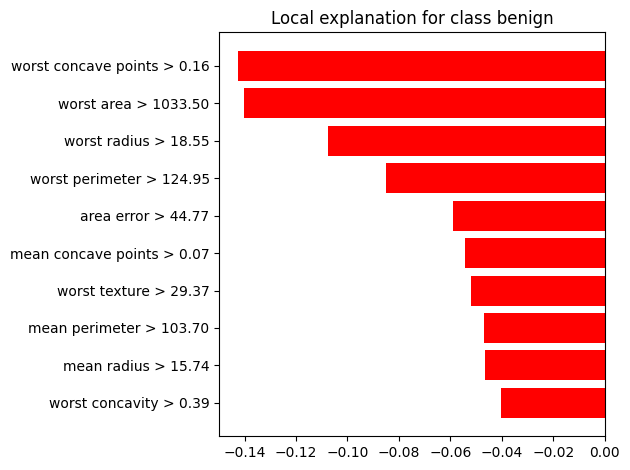


SHAP Values Shape: (100, 30)


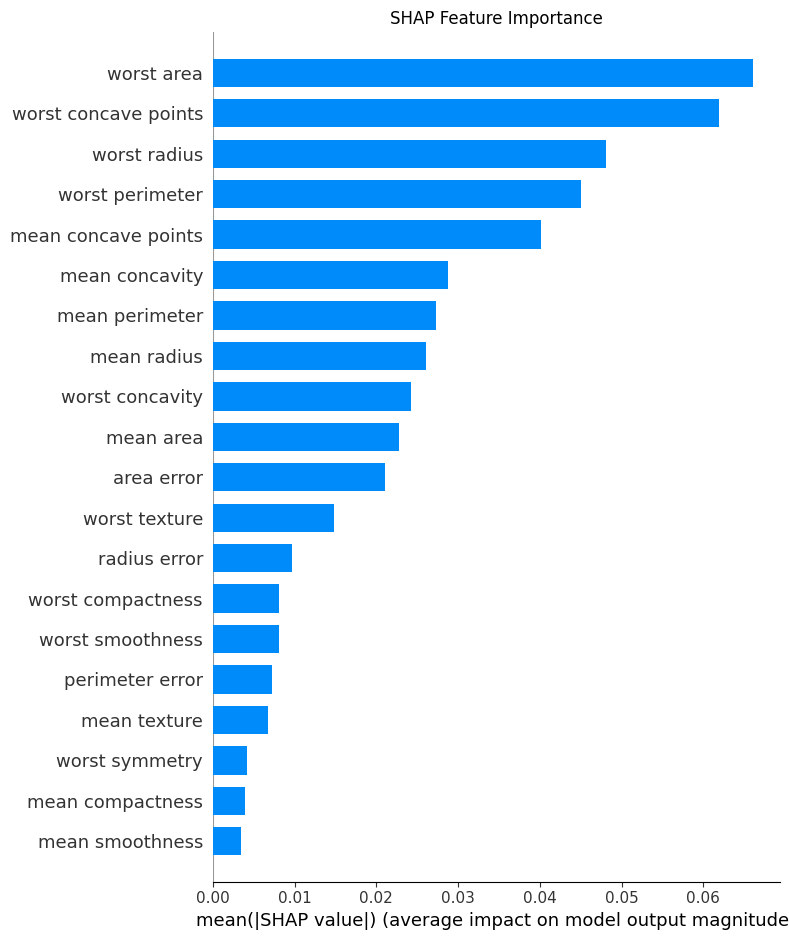

In [2]:
!pip -q install lime shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from lime.lime_tabular import LimeTabularExplainer

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset Shape:", X.shape)
print("Feature Names:", list(X.columns))
print("Target Classes:", list(data.target_names))
print("\nFirst Five Records:")
display(X.head())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(
    n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nModel Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=data.target_names))

lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=list(X.columns),
    class_names=list(data.target_names),
    mode="classification",
    random_state=42)

instance_index = 0
instance = X_test.iloc[instance_index].to_numpy()

lime_exp = lime_explainer.explain_instance(
    data_row=instance,
    predict_fn=lambda samples: model.predict_proba(
        pd.DataFrame(samples, columns=X.columns)),
    num_features=10,
    num_samples=3000)

actual_class = data.target_names[y_test[instance_index]]
predicted_class = data.target_names[
    model.predict(X_test.iloc[[instance_index]])[0]]

print("\nLIME EXPLANATION")
print("Actual Class:", actual_class)
print("Predicted Class:", predicted_class)

display(lime_exp.show_in_notebook(show_table=True))
fig = lime_exp.as_pyplot_figure()
plt.tight_layout()
plt.show()
shap_explainer = shap.TreeExplainer(model)
X_explain = X_test.iloc[:100]
shap_values = shap_explainer.shap_values(X_explain)

if isinstance(shap_values, list):
    class_shap_values = shap_values[0]
elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    class_shap_values = shap_values[:, :, 0]
else:
    class_shap_values = shap_values

print("\nSHAP Values Shape:", class_shap_values.shape)

shap.summary_plot(
    class_shap_values,
    X_explain,
    plot_type="bar",
    show=False)
plt.title("SHAP Feature Importance")
plt.tight_layout()
plt.show()
